In [3]:
import numpy as np
import pandas as pd

In [4]:
np.random.seed(23)

In [7]:
mu_vec1 = np.array([0, 0, 0])
cov_mat1 = np.array([[1, 0, 0],
                     [0, 1, 0],
                     [0, 0, 1]])

class1_sample = np.random.multivariate_normal(mu_vec1, cov_mat1, 20)

df = pd.DataFrame(class1_sample, columns=['feature1', 'feature2', 'feature3'])
df['target'] = 1


mu_vec2 = np.array([1, 1, 1])
cov_mat2 = np.array([[1, 0, 0],
                     [0, 1, 0],
                     [0, 0, 1]])

class2_sample = np.random.multivariate_normal(mu_vec2, cov_mat2, 20)

df1 = pd.DataFrame(class2_sample, columns=['feature1', 'feature2', 'feature3'])
df1['target'] = 0


# Combine both DataFrames
df = pd.concat([df, df1], ignore_index=True)

# Shuffle the rows
df = df.sample(40)


In [8]:
df.head()

,feature1,feature2,feature3,target
4,-0.287443,0.188357,1.119039,1
21,-0.539168,1.822903,1.203793,0
23,-0.180489,-0.036238,2.551678,0
33,0.175949,-0.382765,0.124468,0
9,-0.380134,-0.007444,-0.414385,1


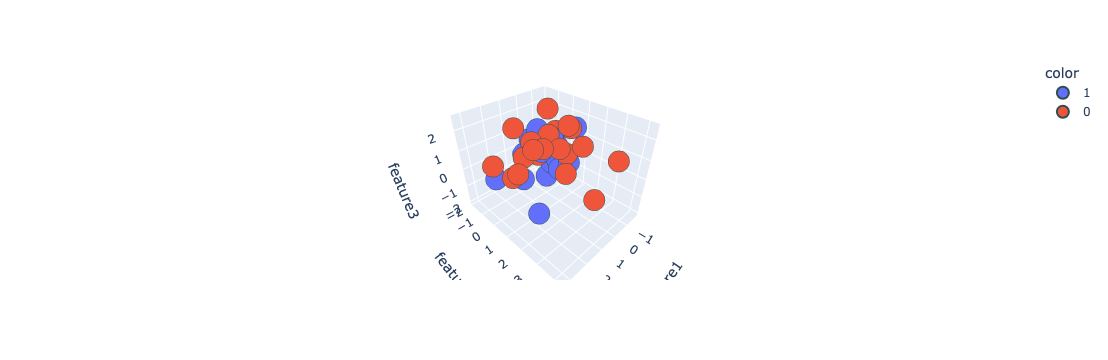

In [10]:
import plotly.express as px
# y_train_trf = y_train.astype(str)
fig = px.scatter_3d(df, x=df['feature1'], y=df['feature2'], z=df['feature3'],
                   color=df['target'].astype('str'))
fig.update_traces(marker=dict(size=12,
                             line=dict(width=2,
                                      color='DarkSlateGrey')),
                 selector=dict(mode='markers'))
fig.show() # we can see the 3d plot

In [11]:
# step 1 - apply standard scaling -- mean centering

from sklearn.preprocessing import StandardScaler
scaler = StandardScaler() # Creates a scaler that will make the features have: mean = 0 and standard deviation = 1

df.iloc[:, 0:3] = scaler.fit_transform(df.iloc[:,0:3])

In [12]:
# step 2 : find covariance matrix
covariance_matrix = np.cov([df.iloc[:, 0], df.iloc[:, 1], df.iloc[:,2]])
print('Covariance Matrix:\n', covariance_matrix)

Covariance Matrix:
 [[1.02564103 0.12754519 0.0220011 ]
 [0.12754519 1.02564103 0.38077301]
 [0.0220011  0.38077301 1.02564103]]


In [17]:
# step 3 : finding eigen values and vectors
eigen_values, eigen_vectors = np.linalg.eig(covariance_matrix)

In [18]:
eigen_values

array([1.43426031, 1.01241414, 0.63024863])

In [19]:
eigen_vectors

array([[ 0.25457851,  0.94776611,  0.19216967],
       [ 0.70061624, -0.04378701, -0.71219351],
       [ 0.66657833, -0.31594635,  0.67516756]])

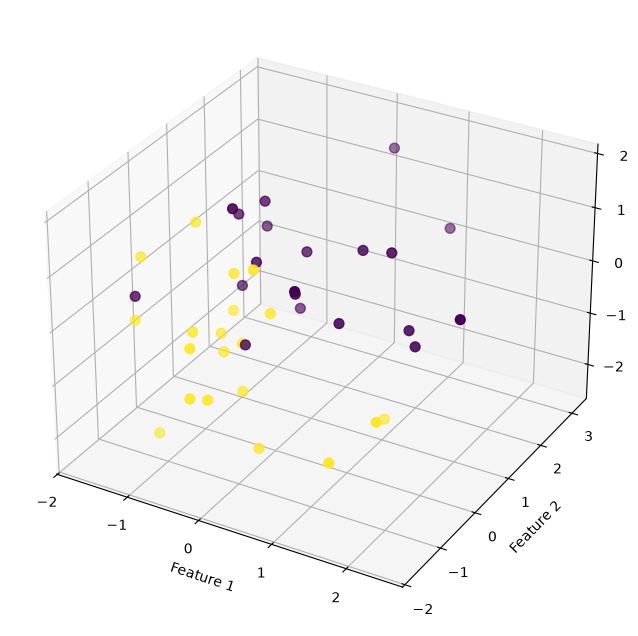

In [24]:
# just plotting

import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
from mpl_toolkits.mplot3d import proj3d
from matplotlib.patches import FancyArrowPatch


class Arrow3D(FancyArrowPatch):
    def __init__(self, xs, ys, zs, *args, **kwargs):
        super().__init__((0, 0), (0, 0), *args, **kwargs)
        self._verts3d = xs, ys, zs

    def do_3d_projection(self):
        xs3d, ys3d, zs3d = self._verts3d
        xs, ys, zs = proj3d.proj_transform(
            xs3d, ys3d, zs3d, self.axes.M
        )
        self.set_positions(
            (xs[0], ys[0]),
            (xs[1], ys[1])
        )
        return np.min(zs)


fig = plt.figure(figsize=(8, 8))
ax = fig.add_subplot(111, projection='3d')

# Plot the data points
ax.scatter(
    df.iloc[:, 0],
    df.iloc[:, 1],
    df.iloc[:, 2],
    c=df['target'],
    s=50
)

# Labels
ax.set_xlabel('Feature 1')
ax.set_ylabel('Feature 2')
ax.set_zlabel('Feature 3')

plt.show()

In [25]:
# we have taken out our top 2 eigen vectors
pc = eigen_vectors[0:2]
pc

array([[ 0.25457851,  0.94776611,  0.19216967],
       [ 0.70061624, -0.04378701, -0.71219351]])

In [28]:
transformed_df = np.dot(df.iloc[:,0:3],pc.T)
# our data shpe is (40,3) and and pc is (2,3) and then transposed to (3,2)- 
# new shape will be 40,2
new_df = pd.DataFrame(transformed_df, columns=['PC1', 'PC2'])
new_df['target'] = df['target'].values
new_df.head()

,PC1,PC2,target
0,-0.115101,-0.740298,1
1,1.079389,-0.998612,0
2,-0.009572,-1.605655,0
3,-0.623292,0.197699,0
4,-0.552401,0.213774,1


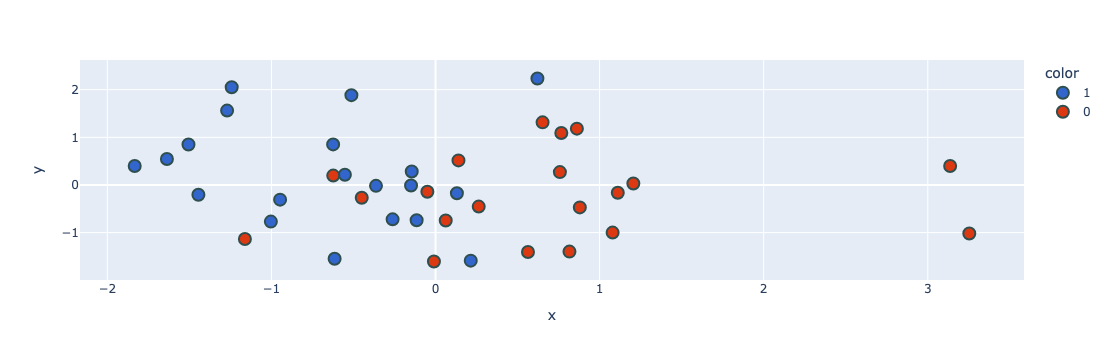

In [29]:

new_df['target'] = new_df['target'].astype('str')
fig = px.scatter(x=new_df['PC1'],
                 y=new_df['PC2'],
                 color=new_df['target'],
                 color_discrete_sequence=px.colors.qualitative.G10
                )

fig.update_traces(marker=dict(size=12,
                              line=dict(width=2,
                                        color='DarkSlateGrey')),
                  selector=dict(mode='markers'))
fig.show()